<a href="https://colab.research.google.com/github/mahapatramadhu-ops/python-/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("/content/labeled_data.csv")

print("Dataset shape:", df.shape)

print("\nFirst five records:")
print(df.head())

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

Saving labeled_data.csv to labeled_data (2).csv
Dataset shape: (24783, 7)

First five records:
   Unnamed: 0  count  hate_speech  offensive_language  neither  class  \
0           0      3            0                   0        3      2   
1           1      3            0                   3        0      1   
2           2      3            0                   3        0      1   
3           3      3            0                   2        1      1   
4           4      6            0                   6        0      1   

                                               tweet  
0  !!! RT @mayasolovely: As a woman you shouldn't...  
1  !!!!! RT @mleew17: boy dats cold...tyga dwn ba...  
2  !!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...  
3  !!!!!!!!! RT @C_G_Anderson: @viva_based she lo...  
4  !!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...  

Column names:
Index(['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither',
       'class', 'tweet'],
      dtype='obje

Total records: 24783

Class distribution:
class
0     1430
1    19190
2     4163
Name: count, dtype: int64


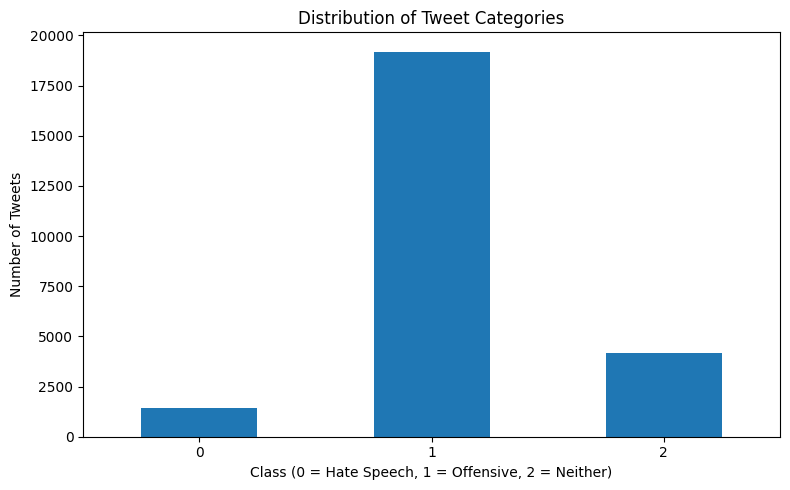

In [ ]:
df = df.dropna(subset=["tweet", "class"])

df["tweet"] = df["tweet"].astype(str)

df["class"] = df["class"].astype(int)

df = df[df["class"].isin([0, 1, 2])]
df = df[df["tweet"].str.strip() != ""]

X = df["tweet"]
y = df["class"]

print("Total records:", len(df))

print("\nClass distribution:")
print(y.value_counts().sort_index())
y.value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Tweet Categories")
plt.xlabel("Class (0 = Hate Speech, 1 = Offensive, 2 = Neither)")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 19826
Testing records: 4957


In [ ]:
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=20000,
    sublinear_tf=True
)

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

results = []
trained_models = {}

for name, classifier in models.items():

    print("\nTraining model:", name)

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=20000,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1 Score": f1
    })

    trained_models[name] = model

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=[
            "Hate Speech",
            "Offensive Language",
            "Neither"
        ],
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nFinal Model Comparison:")
print(results_df.round(4).to_string(index=False))


Training model: Logistic Regression

Classification Report:
                    precision    recall  f1-score   support

       Hate Speech       0.36      0.58      0.44       286
Offensive Language       0.96      0.88      0.92      3838
           Neither       0.77      0.93      0.84       833

          accuracy                           0.87      4957
         macro avg       0.70      0.79      0.73      4957
      weighted avg       0.90      0.87      0.88      4957


Training model: Naive Bayes

Classification Report:
                    precision    recall  f1-score   support

       Hate Speech       1.00      0.00      0.01       286
Offensive Language       0.81      1.00      0.89      3838
           Neither       0.90      0.26      0.40       833

          accuracy                           0.81      4957
         macro avg       0.90      0.42      0.43      4957
      weighted avg       0.84      0.81      0.76      4957


Training model: Linear SVM

Classificat

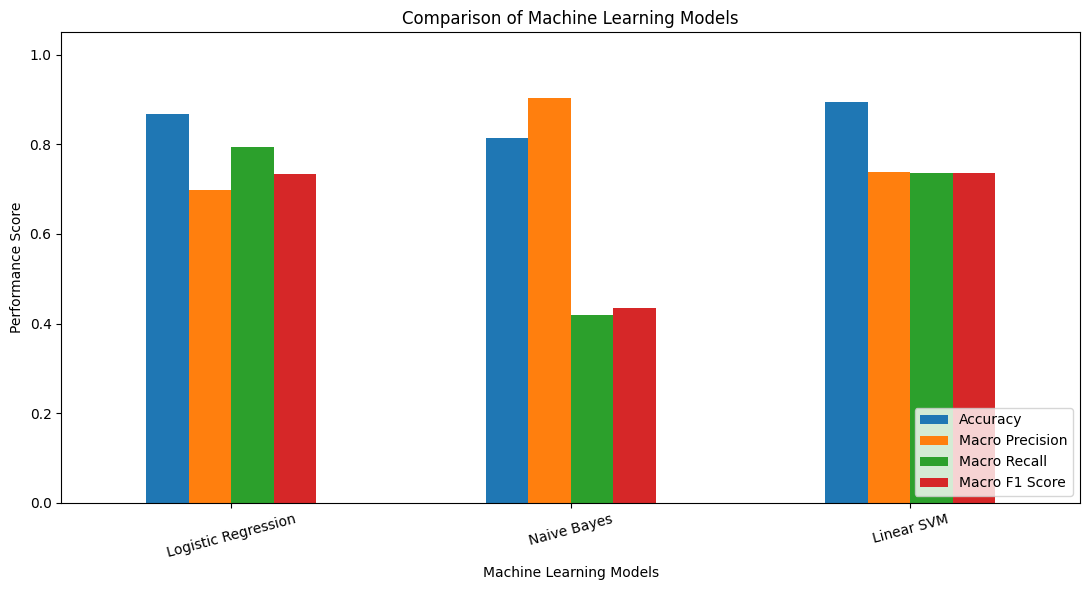

In [ ]:
results_df.set_index("Model")[
    [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1 Score"
    ]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

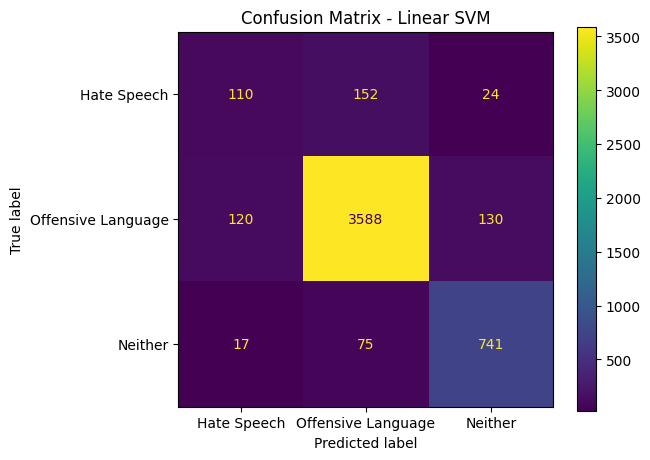

Best model based on macro F1: Linear SVM


In [ ]:
best_model_name = results_df.sort_values(
    by="Macro F1 Score",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Hate Speech",
        "Offensive Language",
        "Neither"
    ]
)

disp.plot(values_format="d")

plt.title("Confusion Matrix - " + best_model_name)
plt.tight_layout()
plt.show()

print("Best model based on macro F1:", best_model_name)

In [ ]:
new_tweet = input("Enter a tweet: ")

prediction = best_model.predict([new_tweet])[0]

labels = {
    0: "Hate Speech",
    1: "Offensive Language",
    2: "Neither"
}

print("Predicted category:", labels[prediction])

Enter a tweet: you are bad
Predicted category: Offensive Language


In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

# Load dataset
df = pd.read_csv("labeled_data.csv")

# Prepare data
df = df.dropna(subset=["tweet", "class"])

df["tweet"] = df["tweet"].astype(str)
df["class"] = df["class"].astype(int)

df = df[df["class"].isin([0, 1, 2])]
df = df[df["tweet"].str.strip() != ""]

X = df["tweet"]
y = df["class"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

results = []

# Train and evaluate models
for name, classifier in models.items():

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=20000,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    macro_f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro-F1 Score": macro_f1,
        "Weighted-F1 Score": weighted_f1
    })

results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Macro-F1 Score  Weighted-F1 Score
0  Logistic Regression  0.868065        0.734081           0.877822
1          Naive Bayes  0.814404        0.434333           0.759570
2           Linear SVM  0.895501        0.736023           0.893937


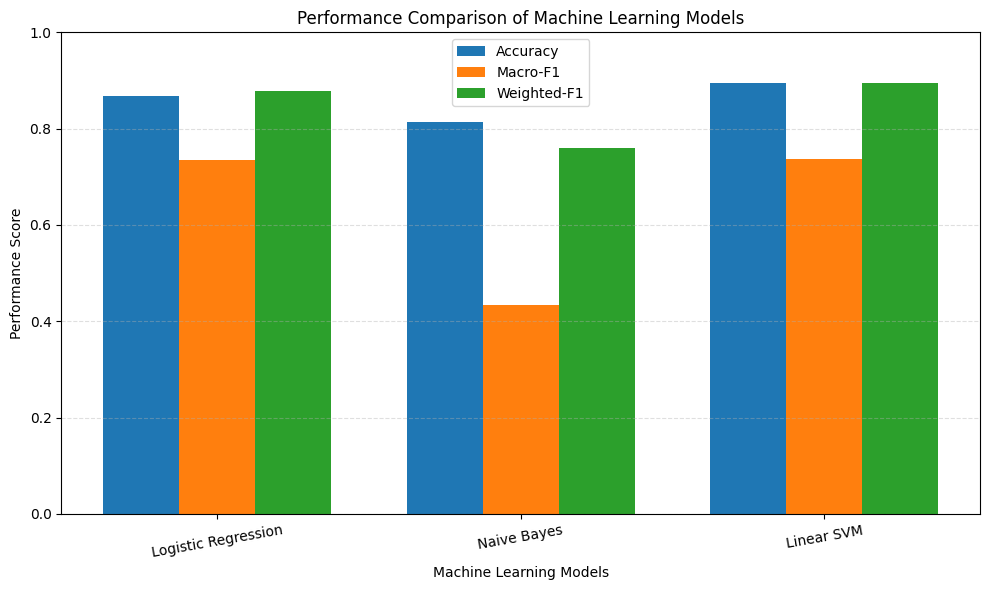

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data from your table
models = ['Logistic Regression', 'Naive Bayes', 'Linear SVM']

accuracy = [0.868065, 0.814404, 0.895501]
macro_f1 = [0.734081, 0.434333, 0.736023]
weighted_f1 = [0.877822, 0.759570, 0.893937]

# Bar positions
x = np.arange(len(models))
width = 0.25

# Create graph
plt.figure(figsize=(10, 6))

plt.bar(x - width, accuracy, width, label='Accuracy')
plt.bar(x, macro_f1, width, label='Macro-F1')
plt.bar(x + width, weighted_f1, width, label='Weighted-F1')

# Labels and title
plt.xlabel('Machine Learning Models')
plt.ylabel('Performance Score')
plt.title('Performance Comparison of Machine Learning Models')

plt.xticks(x, models, rotation=10)
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

# Save graph for your research paper
plt.savefig('model_performance_comparison.png', dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
results_df.to_csv(
    "research_model_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
